# Conservation, advection and diffusion

How can a spatial model move and spread material without creating it?

Fall 2024.


## Predict
This original passive-scalar fixture uses periodic boundaries. Predict the displacement in 0.5 s for a=0.2 m/s and distinguish physical from numerical spreading. Record the predicted total before running.

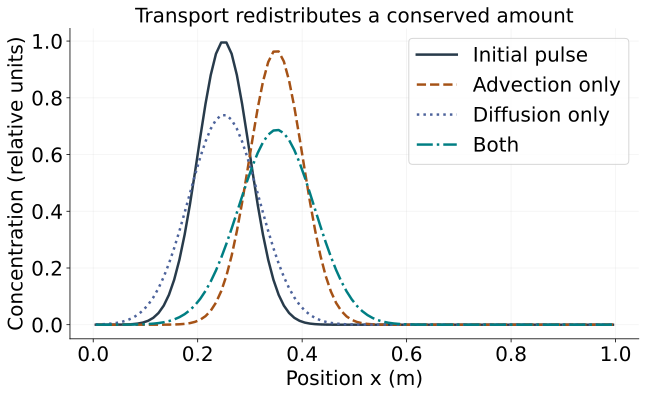

[{'label': 'advection',
  'dt': 0.041666666666666664,
  'steps': 12,
  'courant': 0.8333333333333333,
  'diffusion_number': 0.0,
  'mass_initial': 0.12407174345996842,
  'mass_final': 0.12407174345996844,
  'max_mass_drift': 2.7755575615628914e-17},
 {'label': 'diffusion',
  'dt': 0.020833333333333332,
  'steps': 24,
  'courant': 0.0,
  'diffusion_number': 0.41666666666666663,
  'mass_initial': 0.12407174345996842,
  'mass_final': 0.12407174345996842,
  'max_mass_drift': 2.7755575615628914e-17},
 {'label': 'both',
  'dt': 0.013888888888888888,
  'steps': 36,
  'courant': 0.2777777777777778,
  'diffusion_number': 0.27777777777777773,
  'mass_initial': 0.12407174345996842,
  'mass_final': 0.12407174345996844,
  'max_mass_drift': 2.7755575615628914e-17}]

In [1]:
import numpy as np
from demo import solve, conservative_step, run
from IPython.display import SVG, display
report = run()
display(SVG(filename="transport-pulse.svg"))
report["cases"]

## Implement a guided balance
Translate the supplied cell-balance equation into the function below. The starter expression already runs; replace it with an equivalent explicit loop to practice interface indexing. This is the worked example, not an assigned-exercise answer.

In [2]:
def my_step(c, flux, dx, dt):
    c = np.asarray(c, dtype=float)
    flux = np.asarray(flux, dtype=float)
    return c + (dt/dx)*(flux[:-1] - flux[1:])

answer = my_step([1,2,1], [.3,.5,.2,.1], .5, .2)
np.testing.assert_allclose(answer, [.92,2.12,1.04])
print(answer, "amount:", .5*sum(answer))

[0.92 2.12 1.04] amount: 2.04


## Run, interpret, modify
Change only an internal face flux, predict which two cells change, and verify that the boundary account stays fixed. Then halve the pulse grid spacing and explain why the solver changes its time step.

In [3]:
modified = my_step([1,2,1], [.3,.7,.2,.1], .5, .2)
assert abs(.5*sum(modified) - 2.04) < 1e-12
for n in [100,200]:
    x = (np.arange(n)+.5)/n
    r = solve(np.exp(-((x-.25)/.07)**2))
    print(n, r["dt"], r["max_mass_drift"])

100 0.013888888888888888 2.7755575615628914e-17
200 0.00423728813559322 4.163336342344337e-17


## Reflect
Explain why conservation does not prove the pulse shape is correct. Propose an independent direction check and record the model boundary assumption.